# Mini Project 2: Handwritten Digit Classifier
**Skill Nexis — Deep Learning Week 2**

## Objective
Train a fully connected neural network on the MNIST dataset to classify handwritten digits from **0 to 9**.

### Required output
- Display sample predictions.
- Report test accuracy and a confusion matrix.
- Show at least five incorrect predictions and briefly explain possible reasons.

**Libraries:** TensorFlow/Keras, NumPy, Matplotlib, and scikit-learn.

> The first run may download MNIST and can take a few minutes. Run the notebook cells from top to bottom.


In [1]:
# Step 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [2]:
# Step 2: Load the MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 10s 1us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


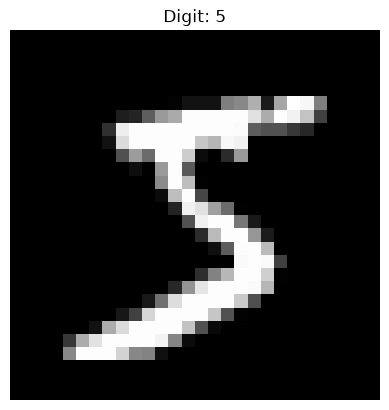

In [3]:
# Step 3: Display one handwritten digit
sample_index = 0
plt.imshow(X_train[sample_index], cmap="gray")
plt.title(f"Digit: {y_train[sample_index]}")
plt.axis("off")
plt.show()


In [4]:
# Step 4: Normalize pixel values to the range 0–1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Step 5: Build and train a fully connected neural network

Each 28 × 28 image is flattened into 784 input values. A hidden layer with 128 neurons uses ReLU, and the output layer has 10 neurons—one for each digit.

In [5]:
# Step 5: Create the neural network
tf.random.set_seed(42)
np.random.seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Step 6: Train the model
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.8968 - loss: 0.3771 - val_accuracy: 0.9558 - val_loss: 0.1705
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9494 - loss: 0.1763 - val_accuracy: 0.9622 - val_loss: 0.1286
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9634 - loss: 0.1268 - val_accuracy: 0.9668 - val_loss: 0.1109
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9715 - loss: 0.0984 - val_accuracy: 0.9685 - val_loss: 0.1014
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9774 - loss: 0.0798 - val_accuracy: 0.9705 - val_loss: 0.0955


In [7]:
# Step 7: Evaluate on the test dataset
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")


Test loss: 0.1046
Test accuracy: 0.9679 (96.79%)


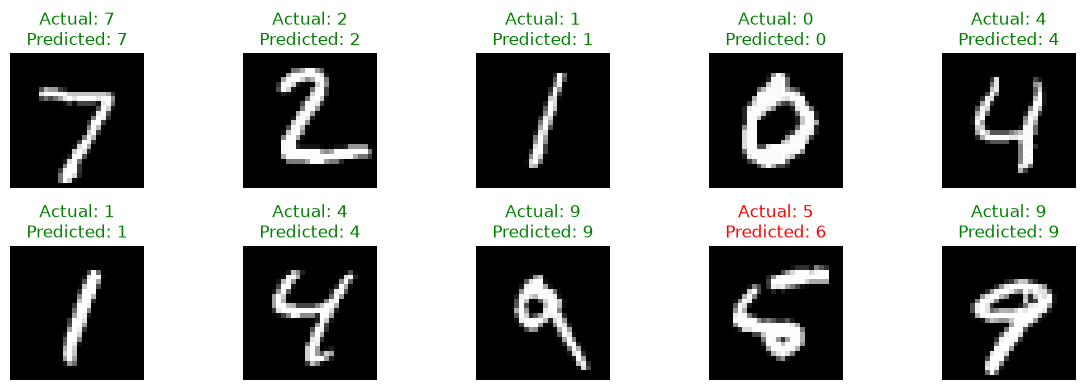

In [8]:
# Step 8: Display sample predictions
sample_probabilities = model.predict(X_test[:10], verbose=0)
sample_predictions = np.argmax(sample_probabilities, axis=1)
plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    color = "green" if sample_predictions[i] == y_test[i] else "red"
    plt.title(f"Actual: {y_test[i]}\nPredicted: {sample_predictions[i]}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()


In [9]:
# Step 9: Calculate accuracy, precision, and recall
all_probabilities = model.predict(X_test, batch_size=256, verbose=0)
y_pred = np.argmax(all_probabilities, axis=1)
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (macro): {precision_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Recall (macro):    {recall_score(y_test, y_pred, average='macro', zero_division=0):.4f}")


Accuracy:          0.9679
Precision (macro): 0.9679
Recall (macro):    0.9677


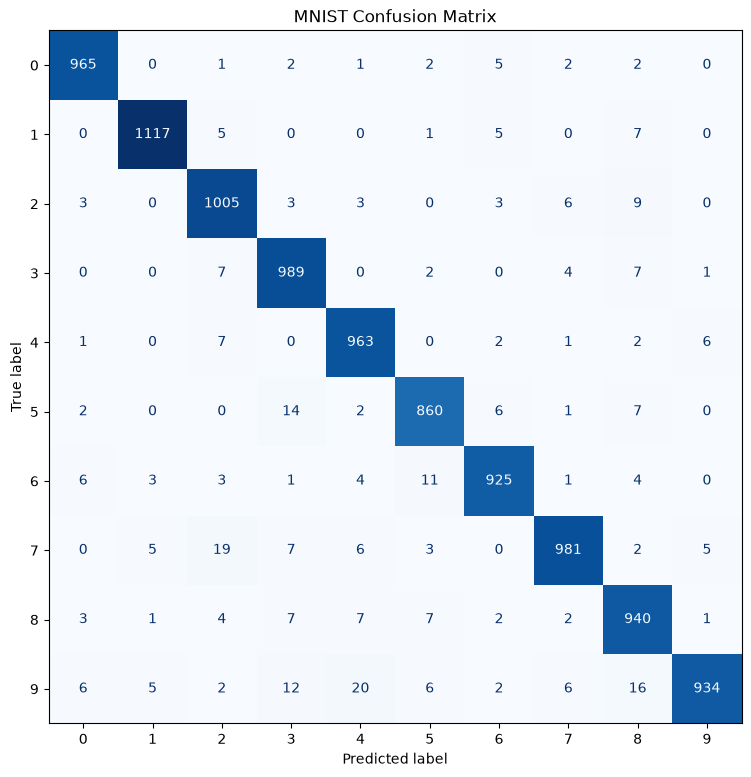

In [10]:
# Step 10: Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
fig, ax = plt.subplots(figsize=(9, 9))
display.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("MNIST Confusion Matrix")
plt.show()


Number of incorrect predictions: 321


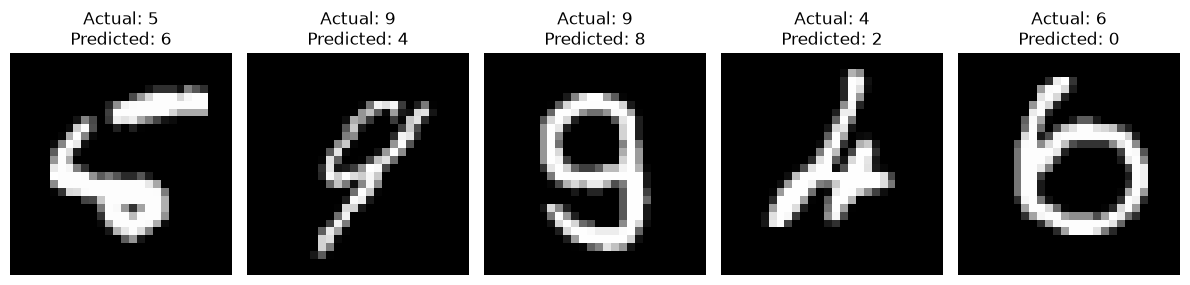


Possible reasons: similar digit shapes, unclear handwriting, unusual writing styles, or insufficient learned patterns.


In [11]:
# Step 11: Find and display at least five incorrect predictions
wrong_indices = np.where(y_pred != y_test)[0]
print("Number of incorrect predictions:", len(wrong_indices))
count = min(5, len(wrong_indices))
if count:
    plt.figure(figsize=(12, 4))
    for plot_index, test_index in enumerate(wrong_indices[:count]):
        plt.subplot(1, count, plot_index + 1)
        plt.imshow(X_test[test_index], cmap="gray")
        plt.title(f"Actual: {y_test[test_index]}\nPredicted: {y_pred[test_index]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()
    print("\nPossible reasons: similar digit shapes, unclear handwriting, unusual writing styles, or insufficient learned patterns.")
else:
    print("No incorrect predictions were found in this run.")


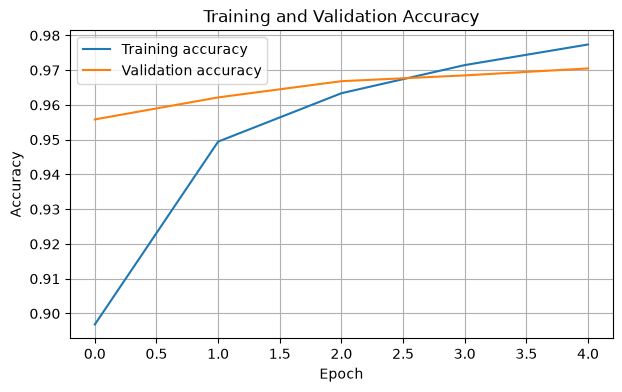

In [12]:
# Step 12: Plot training and validation accuracy
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


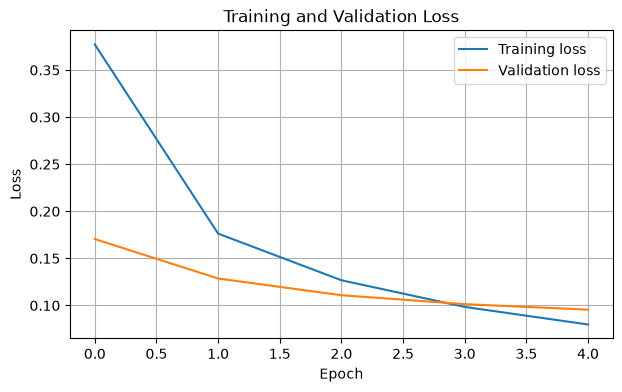

In [13]:
# Step 13: Plot training and validation loss
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


## Short error analysis and conclusion

The confusion matrix shows which digits the model predicts correctly and which it confuses with other digits. Incorrect predictions can happen when two digits look alike, handwriting is unclear, or the model has not learned a particular writing style.

This project demonstrates a basic deep-learning workflow: loading and normalizing MNIST, training a fully connected neural network, evaluating classification metrics, examining errors, and plotting training/validation performance.